<a href="https://colab.research.google.com/github/rosemaria96/Telecom-Customer-Churn-Analysis-with-Risk-Based-Decision-Support/blob/main/Telecom_Customer_Churn_Analysis_with_Risk_Based_Decision_Support.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
from google.colab import files
uploaded = files.upload()

Saving Tele_Customer_Churn.csv to Tele_Customer_Churn (1).csv


In [15]:
# Module 1: Data Loading & Sanity Checks
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="whitegrid")

# Load datset
df = pd.read_csv("Tele_Customer_Churn.csv")

print(df.head())
df.info()
print(df.describe())
print(df.describe(include='all'))
print(df.shape)

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [16]:

#Module 2 : Data Cleaning

# checking missing values
print(df.isnull().sum)
print(df.isnull().values.any())
df.isin([" ", "NA", "N/A", "?", "Unknown", "NaN"]).sum()

# replacing hidden missing values
df.replace(["NA", "N/A", "?", "Unknown", " ", "NaN"], np.nan, inplace = True)

# Converting to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# checking
df.info()
print(df.isnull().sum())

# fill missing numeric values with median
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

#verify
print(df.isnull().sum())

#Drop Non-Analytical Columns
df.drop(columns=['customerID'], inplace=True)

#Convert Churn to Numeric
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

<bound method DataFrame.sum of       customerID  gender  SeniorCitizen  Partner  Dependents  tenure  \
0          False   False          False    False       False   False   
1          False   False          False    False       False   False   
2          False   False          False    False       False   False   
3          False   False          False    False       False   False   
4          False   False          False    False       False   False   
...          ...     ...            ...      ...         ...     ...   
7038       False   False          False    False       False   False   
7039       False   False          False    False       False   False   
7040       False   False          False    False       False   False   
7041       False   False          False    False       False   False   
7042       False   False          False    False       False   False   

      PhoneService  MultipleLines  InternetService  OnlineSecurity  ...  \
0            False          F

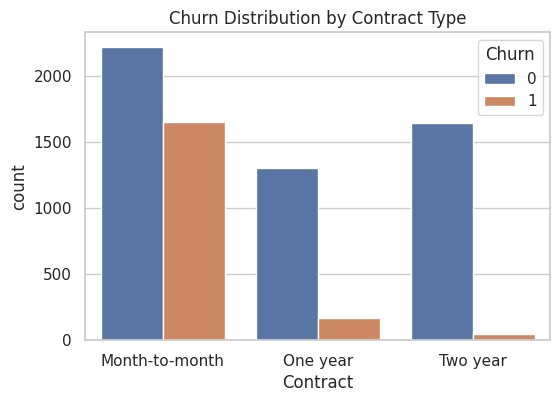

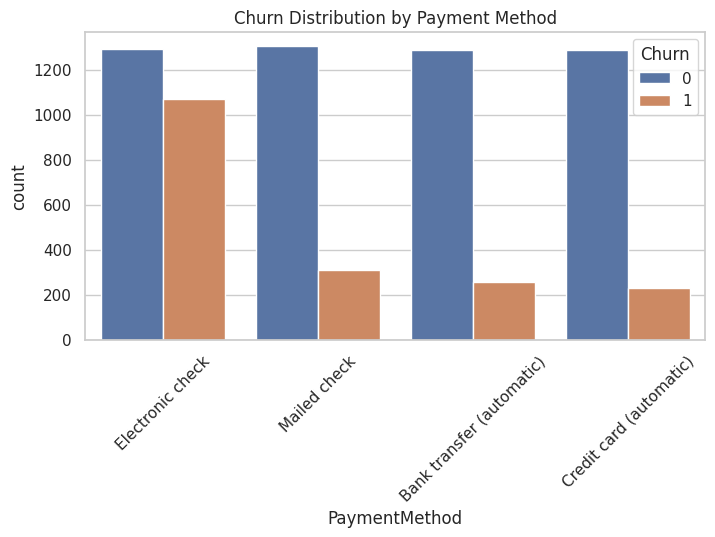

Numeric Columns: ['tenure', 'MonthlyCharges', 'TotalCharges']


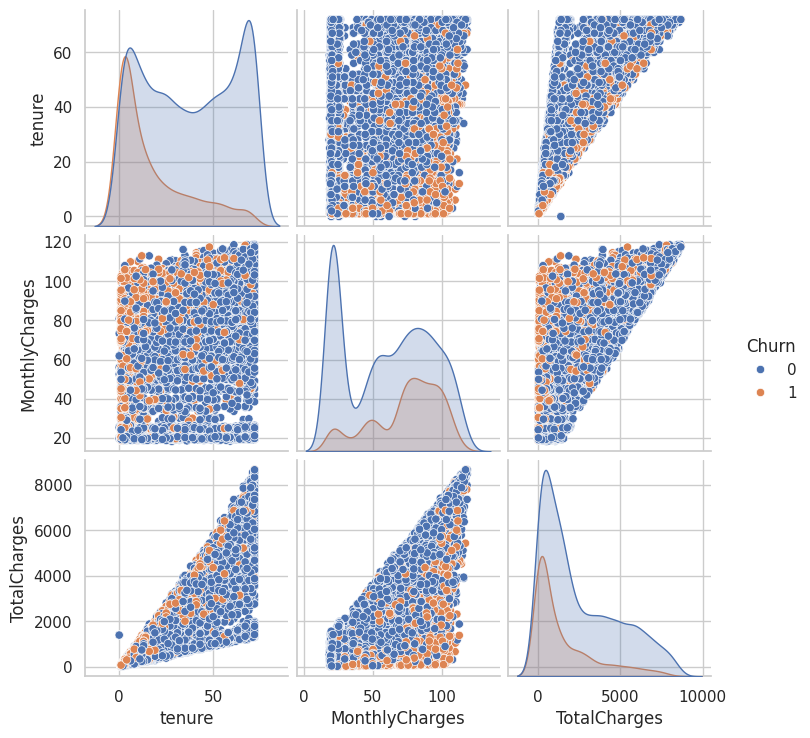

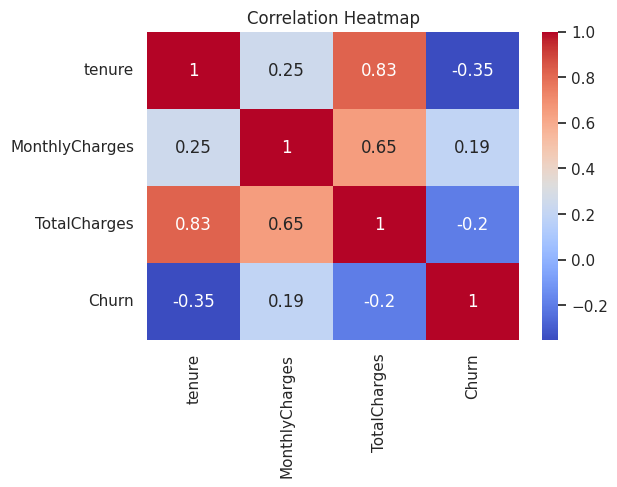

In [17]:
# Module 3: EDA

# Visualize Churn vs Contract
plt.figure(figsize=(6,4))
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title("Churn Distribution by Contract Type")
plt.show()

# Visualize Churn vs PaymentMethod
plt.figure(figsize=(8,4))
sns.countplot(x='PaymentMethod', hue='Churn', data=df)
plt.xticks(rotation=45)
plt.title("Churn Distribution by Payment Method")
plt.show()

numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
print("Numeric Columns:", numeric_cols)

# Pairplot for numeric features
sns.pairplot(df[numeric_cols + ['Churn']], hue='Churn')
plt.show()


# Correlation Heatmap
plt.figure(figsize=(6,4))
sns.heatmap(df[numeric_cols + ['Churn']].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

In [18]:
# Module 4: Feature Engineering
# Example: Tenure Bucket
df['tenure_bucket'] = pd.cut(df['tenure'], bins=[-1,12,24,48,60,72],
                             labels=['0-12','12-24','24-48','48-60','60-72'])

# Example: High Monthly Charges Flag
df['HighMonthlyCharges'] = df['MonthlyCharges'].apply(lambda x: 1 if x > 80 else 0)


Risk
Low                                  3579
High - Immediate Retention Action    1908
Medium - Monitor                     1556
Name: count, dtype: int64

Churn % by Risk Level:
 Churn                                      0          1
Risk                                                   
High - Immediate Retention Action  48.060797  51.939203
Low                                90.528080   9.471920
Medium - Monitor                   65.359897  34.640103


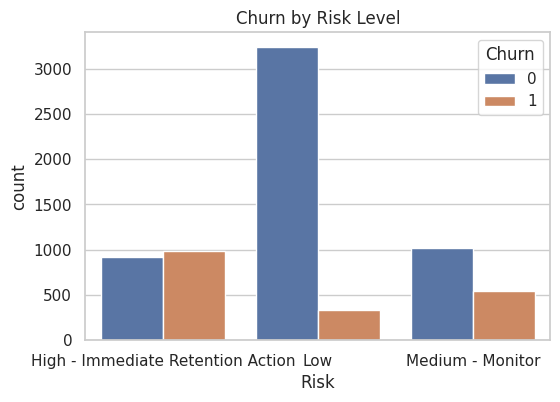

In [19]:
# Module 5: Risk based Decision Support

#Decision Rules
def assign_risk(row):
    if row['tenure'] < 12 and row['Contract'] == 'Month-to-month':
        return 'High - Immediate Retention Action'
    elif row['MonthlyCharges'] > 80 and row['OnlineSecurity'] == 'No':
        return 'Medium - Monitor'
    elif row['SeniorCitizen'] == 1 and row['TechSupport'] == 'No':
        return 'Medium - Monitor'
    else:
        return 'Low'

df['Risk'] = df.apply(assign_risk, axis=1)

# Show Risk Distribution
print(df['Risk'].value_counts())

# Risk vs Churn Crosstab
risk_churn = pd.crosstab(df['Risk'], df['Churn'], normalize='index')*100
print("\nChurn % by Risk Level:\n", risk_churn)

# Visualize Risk vs Churn
plt.figure(figsize=(6,4))
sns.countplot(x='Risk', hue='Churn', data=df)
plt.title("Churn by Risk Level")
plt.show()


In [20]:
#Exporting Decision Rules
rules = [
    {"Rule": "tenure < 12 & Contract = Month-to-month", "Risk": "High - Immediate Retention Action"},
    {"Rule": "MonthlyCharges > 80 & OnlineSecurity = No", "Risk": "Medium - Monitor"},
    {"Rule": "SeniorCitizen = 1 & TechSupport = No", "Risk": "Medium - Monitor"},
]

pd.DataFrame(rules).to_csv("churn_decision_rules.csv", index=False)

#Save final cleaned dataset
df.to_csv("Tele_Customer_Churn_Cleaned.csv", index=False)

In [21]:
# Module 6: Train/Test Split & Preprocessing
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, precision_score,
                             recall_score, f1_score, confusion_matrix)

# Drop derived/label-like columns so the models learn from raw customer attributes only
X = df.drop(columns=['Churn', 'Risk', 'tenure_bucket'])
y = df['Churn']

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

# 80:20 stratified split keeps the churn ratio equal in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate - train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (5634, 20) | Test: (1409, 20)
Churn rate - train: 0.265 | test: 0.265


In [22]:
# Module 7: Model Training & Evaluation
def ks_statistic(y_true, y_score):
    fpr, tpr, _ = roc_curve(y_true, y_score)
    return np.max(tpr - fpr)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            class_weight='balanced_subsample',
                                            random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fitted, rows = {}, []

for name, clf in models.items():
    pipe = Pipeline([('prep', preprocess), ('model', clf)])
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc').mean()
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    fitted[name] = (pipe, proba)
    rows.append({
        'Model': name,
        'CV AUC (train)': round(cv_auc, 3),
        'Test AUC': round(roc_auc_score(y_test, proba), 3),
        'KS': round(ks_statistic(y_test, proba), 3),
        'Precision': round(precision_score(y_test, pred), 3),
        'Recall': round(recall_score(y_test, pred), 3),
        'F1': round(f1_score(y_test, pred), 3)
    })

# Baseline: your rule-based risk score (High=2, Medium=1, Low=0) on the same test rows
risk_score = df.loc[X_test.index, 'Risk'].map(
    lambda r: 2 if r.startswith('High') else (1 if r.startswith('Medium') else 0))
rows.append({'Model': 'Rule-based risk (baseline)',
             'CV AUC (train)': np.nan,
             'Test AUC': round(roc_auc_score(y_test, risk_score), 3),
             'KS': round(ks_statistic(y_test, risk_score), 3),
             'Precision': np.nan, 'Recall': np.nan, 'F1': np.nan})

results = pd.DataFrame(rows).set_index('Model')
print(results)

                            CV AUC (train)  Test AUC     KS  Precision  \
Model                                                                    
Logistic Regression                  0.845     0.841  0.519      0.505   
Random Forest                        0.845     0.841  0.543      0.549   
Gradient Boosting                    0.848     0.843  0.540      0.674   
Rule-based risk (baseline)             NaN     0.763  0.477        NaN   

                            Recall     F1  
Model                                      
Logistic Regression          0.781  0.613  
Random Forest                0.735  0.629  
Gradient Boosting            0.524  0.589  
Rule-based risk (baseline)     NaN    NaN  


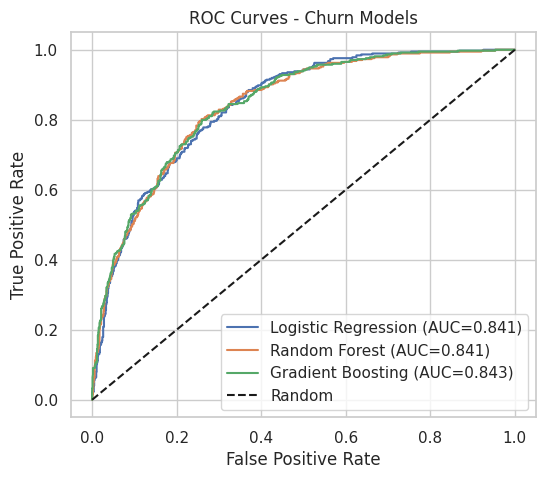

Best model: Gradient Boosting
               Pred: Stay  Pred: Churn
Actual: Stay          940           95
Actual: Churn         178          196


In [23]:
# Module 8: ROC Curves & Confusion Matrix of the best model
plt.figure(figsize=(6,5))
for name, (pipe, proba) in fitted.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
plt.plot([0,1],[0,1],'k--', label='Random')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Churn Models'); plt.legend(); plt.show()

best_name = results.drop('Rule-based risk (baseline)')['Test AUC'].idxmax()
best_pipe, best_proba = fitted[best_name]
print("Best model:", best_name)
print(pd.DataFrame(confusion_matrix(y_test, (best_proba >= 0.5).astype(int)),
                   index=['Actual: Stay', 'Actual: Churn'],
                   columns=['Pred: Stay', 'Pred: Churn']))

Contract            0.073013
tenure              0.044158
TotalCharges        0.010917
MonthlyCharges      0.010726
InternetService     0.008603
TechSupport         0.008075
OnlineSecurity      0.006620
MultipleLines       0.004401
PaymentMethod       0.002798
PaperlessBilling    0.002429
dtype: float64


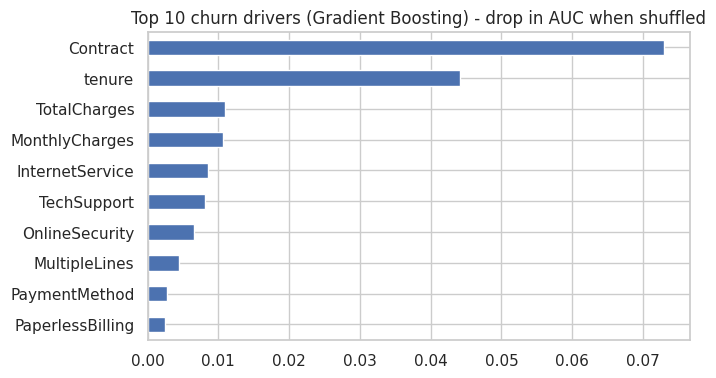

In [24]:
# Module 9: What drives churn? (Permutation importance on raw features)
from sklearn.inspection import permutation_importance

imp = permutation_importance(best_pipe, X_test, y_test, scoring='roc_auc',
                             n_repeats=10, random_state=42, n_jobs=-1)
importance = (pd.Series(imp.importances_mean, index=X_test.columns)
                .sort_values(ascending=False).head(10))
print(importance)

importance.sort_values().plot(kind='barh', figsize=(7,4))
plt.title(f'Top 10 churn drivers ({best_name}) - drop in AUC when shuffled')
plt.show()

In [25]:
# Module 10: Decile / Lift Table (business view: who to call first)
scored = pd.DataFrame({'churn': y_test.values, 'score': best_proba})
scored['decile'] = pd.qcut(scored['score'].rank(method='first'), 10,
                           labels=range(10, 0, -1))   # 1 = highest risk
lift = (scored.groupby('decile', observed=True)
              .agg(customers=('churn', 'size'), churners=('churn', 'sum'))
              .sort_index(key=lambda s: s.astype(int)))
lift['churn_rate_%'] = (lift['churners'] / lift['customers'] * 100).round(1)
lift['cum_churners_captured_%'] = (lift['churners'].cumsum() / lift['churners'].sum() * 100).round(1)
lift['lift'] = (lift['churn_rate_%'] / (y_test.mean() * 100)).round(2)
print(lift)

        customers  churners  churn_rate_%  cum_churners_captured_%  lift
decile                                                                  
1             141       109          77.3                     29.1  2.91
2             141        83          58.9                     51.3  2.22
3             141        55          39.0                     66.0  1.47
4             141        49          34.8                     79.1  1.31
5             140        25          17.9                     85.8  0.67
6             141        29          20.6                     93.6  0.78
7             141        11           7.8                     96.5  0.29
8             141        10           7.1                     99.2  0.27
9             141         2           1.4                     99.7  0.05
10            141         1           0.7                    100.0  0.03


In [26]:
# Module 11: Save outputs
import joblib
results.to_csv("model_comparison.csv")
lift.to_csv("decile_lift_table.csv")
joblib.dump(best_pipe, "best_churn_model.joblib")

['best_churn_model.joblib']